# Stage 1a: Preprocess LIAR

**Stage:** 1 (preprocessing) · **Runs on:** Kaggle and locally

| | |
|---|---|
| Input | `train.tsv`, `valid.tsv`, `test.tsv` (LIAR, PolitiFact statements) |
| Output | `liar_cleaned.csv` (the only file saved; tables and plots are shown in this notebook) |
| Used for | Task A classification (without half-true), Task B regression (all six ratings) |

LIAR is the only dataset with **six** ratings, so it keeps two targets:

| Rating | `score` (regression) | `label` (classification) |
|---|---|---|
| pants-fire | 0 | 1 misleading |
| false | 1 | 1 misleading |
| barely-true | 2 | 1 misleading |
| half-true | 3 | *empty: not used for classification* |
| mostly-true | 4 | 0 reliable |
| true | 5 | 0 reliable |

In [1]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("01a")

misinfo_utils | stage 01a | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\01_preprocess


In [2]:
MIN_WORDS = 3   # statements are short; drop anything under 3 words

## 1. Load the three files

The files have **no header row**. Without `header=None`, pandas would use the first statement of
each file as column names and lose that row. `QUOTE_NONE` stops quotation marks inside statements
from confusing the reader.

In [3]:
import csv

LIAR_COLUMNS = ["id", "rating", "statement", "subject", "speaker", "job", "state", "party",
                "barely_true_count", "false_count", "half_true_count", "mostly_true_count",
                "pants_fire_count", "context"]

parts = []
for name in ["train.tsv", "valid.tsv", "test.tsv"]:
    part = pd.read_csv(mu.find_file(name), sep="\t", header=None, quoting=csv.QUOTE_NONE,
                       on_bad_lines="skip", dtype=str)
    part = part.iloc[:, :len(LIAR_COLUMNS)]
    part.columns = LIAR_COLUMNS[:part.shape[1]]
    print(f"{name:10s} {len(part):>6,} rows")
    parts.append(part)

# The original train/valid/test split is not kept: Stage 2 makes one split for all datasets.
raw = pd.concat(parts, ignore_index=True)
print("Total:", f"{len(raw):,}", "rows")
raw.head(3)

train.tsv  10,269 rows
valid.tsv   1,284 rows
test.tsv    1,283 rows
Total: 12,836 rows


,id,rating,statement,subject,speaker,job,state,party,barely_true_count,false_count,half_true_count,mostly_true_count,pants_fire_count,context
0,2635.json,false,Says the Annies List political group supports third-trimester abortions on demand.,abortion,dwayne-bohac,State representative,Texas,republican,0,1,0,0,0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started when natural gas took off that started to begin i...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0,0,1,1,0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt ...",foreign-policy,barack-obama,President,Illinois,democrat,70,71,160,163,9,Denver


## 2. Original ratings

Only `statement` and `rating` are used. Speaker, party, context and the five credit-history
counts are dropped: the website only receives text, and the counts include the statement's own
rating, which would leak the answer.

rating
half-true      2638
false          2511
mostly-true    2466
barely-true    2108
true           2063
pants-fire     1050
Name: count, dtype: int64
Unexpected ratings: none


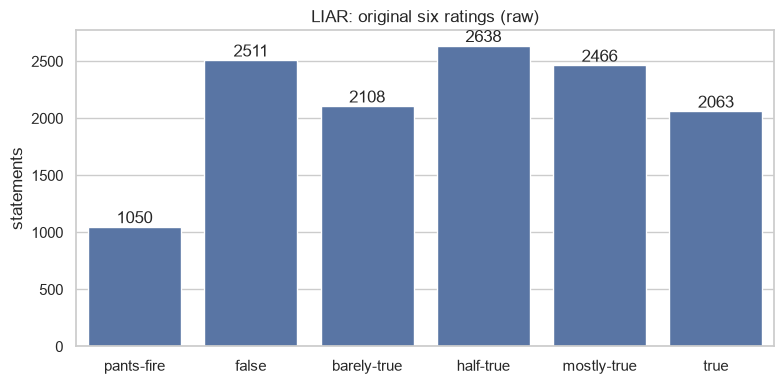

In [4]:
raw["rating"] = raw["rating"].str.strip().str.lower()
order = [mu.SCORE_NAMES[i] for i in range(6)]

rating_counts = raw["rating"].value_counts(dropna=False)
print(rating_counts)

unexpected = sorted(set(raw["rating"].dropna()) - set(mu.LIAR_SCORE))
print("Unexpected ratings:", unexpected or "none")

plt.figure(figsize=(8, 4))
graph = sns.countplot(x=raw["rating"], order=order, color="#4C72B0")
graph.bar_label(graph.containers[0])
plt.title("LIAR: original six ratings (raw)"); plt.xlabel(""); plt.ylabel("statements")
plt.tight_layout(); plt.show()

## 3. Map ratings to `score` and `label`

In [5]:
score = raw["rating"].map(mu.LIAR_SCORE)          # 0-5; empty for unexpected ratings

# Classification label: 0-2 misleading, 4-5 reliable, 3 (half-true) left empty
label = pd.Series(pd.NA, index=raw.index, dtype="Int64")
label[score <= 2] = 1
label[score >= 4] = 0

liar = pd.DataFrame({
    "row_id": mu.make_row_ids(len(raw), "liar"),   # from the raw position, never changes
    "text": raw["statement"],
    "score": score,
    "label": label,
})
print(liar[["score", "label"]].value_counts(dropna=False).sort_index())

score  label
0      1        1050
1      1        2511
2      1        2108
3      <NA>     2638
4      0        2466
5      0        2063
Name: count, dtype: int64


## 4. Shortcut check: statements starting with "Says"

PolitiFact writes paraphrased claims as "Says ...". If that start is much more common in one class,
models may learn the writing habit instead of the content. Report the result; the text is not
changed.

In [6]:
clf_rows = liar.dropna(subset=["label"])
starts_says = clf_rows["text"].fillna("").str.startswith("Says ")
says_check = pd.DataFrame({
    "statements": [starts_says.sum(), (~starts_says).sum()],
    "% misleading": [100 * clf_rows.loc[starts_says, "label"].mean(),
                     100 * clf_rows.loc[~starts_says, "label"].mean()],
}, index=["starts with 'Says'", "other"]).round(1)
says_check

,statements,% misleading
starts with 'Says',2217,61.5
other,7981,54.0


## 5. Clean and remove duplicates

Duplicates are checked on `score`, the finer target: a statement that appears with **different
ratings** is removed completely (all copies), then remaining duplicates are reduced to one.

In [7]:
liar_clean, log = mu.clean_and_deduplicate(liar, MIN_WORDS, target_col="score")
liar_clean = mu.to_clean_schema(liar_clean, "liar")

log["regression_rows (all 6 ratings)"] = len(liar_clean)
log["classification_rows (half-true excluded)"] = int(liar_clean["label"].notna().sum())
pd.Series(log, name="rows").to_frame()   # cleaning log: copy into the Data Processing section of the report

,rows
loaded,12836
after_missing_target,12836
after_empty_text,12836
after_min_length,12826
after_conflict_removal,12815
after_dedup,12791
regression_rows (all 6 ratings),12791
classification_rows (half-true excluded),10163


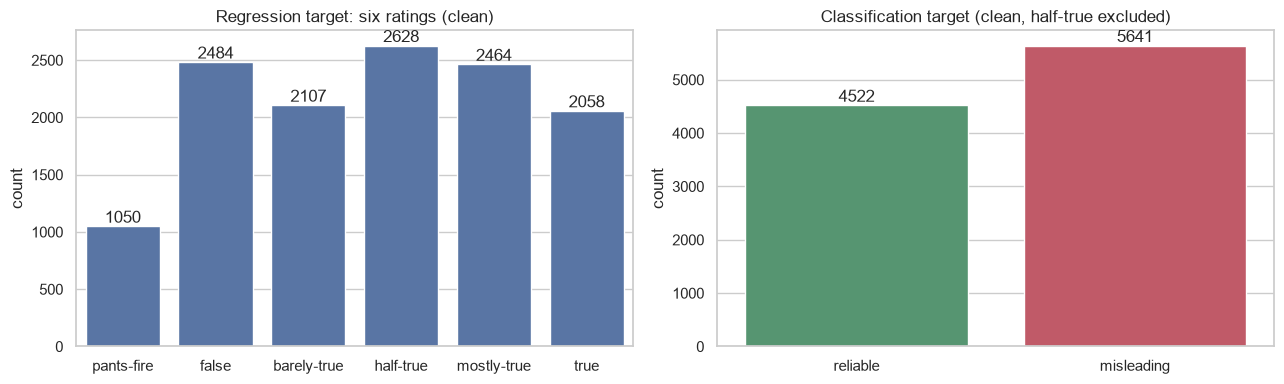

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
graph = sns.countplot(x=liar_clean["score"].astype(int).map(mu.SCORE_NAMES), order=order,
                      color="#4C72B0", ax=axes[0])
graph.bar_label(graph.containers[0])
axes[0].set_title("Regression target: six ratings (clean)"); axes[0].set_xlabel("")

labelled = liar_clean.dropna(subset=["label"])
graph = sns.countplot(x=labelled["label"].astype(int).map(mu.LABEL_NAMES), order=["reliable", "misleading"],
                      hue=labelled["label"].astype(int).map(mu.LABEL_NAMES),
                      palette={"reliable": "#4C9F70", "misleading": "#D1495B"}, legend=False, ax=axes[1])
for c in graph.containers:
    graph.bar_label(c)
axes[1].set_title("Classification target (clean, half-true excluded)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Save

In [9]:
mu.save_clean_dataset(liar_clean, "liar")
liar_clean.head()

Saved 12,791 rows -> D:\misinfo-project\outputs\01_preprocess\liar_cleaned.csv


,row_id,text,label,score,source_dataset,sub_source,n_words,had_url
0,liar_000000,Says the Annies List political group supports third-trimester abortions on demand.,1,1,liar,liar,11,False
1,liar_000001,When did the decline of coal start? It started when natural gas took off that started to begin i...,<NA>,3,liar,liar,24,False
2,liar_000002,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt ...",0,4,liar,liar,19,False
3,liar_000003,Health care reform legislation is likely to mandate free sex change surgeries.,1,1,liar,liar,12,False
4,liar_000004,The economic turnaround started at the end of my term.,<NA>,3,liar,liar,10,False


**Next stage:** `02_merge_and_split` reads this file. On Kaggle, save this notebook with
**Save Version → Save & Run All**, then add it as an input to `02_merge_and_split`.